# Predictive Maintenance Using NASA C-MAPSS

## Phase 4 — Analytics and Visualization

Analyze Remaining Useful Life (RUL) predictions, examine model errors and feature importance, and identify engines that may need maintenance attention.

In [0]:
from pyspark.sql import functions as F

schema = "workspace.predictive_maintenance_rul"

# Load the saved official test evaluation
evaluation = spark.table(f"{schema}.gold_test_evaluation")

print("Total evaluated engines:", evaluation.count())
print("Unique engines:", evaluation.select("unit_number").distinct().count())

print("Mean absolute error:")
display(
    evaluation.select(
        F.avg("absolute_error").alias("mean_absolute_error")
    )
)

# Inspect actual versus predicted RUL
display(
    evaluation.select(
        "unit_number",
        "actual_RUL",
        "predicted_RUL",
        "absolute_error"
    ).orderBy("unit_number").limit(10)
)

Total evaluated engines: 100
Unique engines: 100
Mean absolute error:


mean_absolute_error
20.892802014765838


unit_number,actual_RUL,predicted_RUL,absolute_error
1,112,151.80743830160208,39.807438301602076
2,98,140.7000757291631,42.7000757291631
3,69,58.62785425728279,10.372145742717208
4,82,108.70957947059729,26.70957947059729
5,91,118.32314453217248,27.323144532172478
6,93,137.88848911655674,44.88848911655674
7,91,116.08539250648928,25.085392506489285
8,95,116.68932775511074,21.68932775511074
9,111,133.08384483121054,22.08384483121054
10,96,129.1630912436346,33.1630912436346


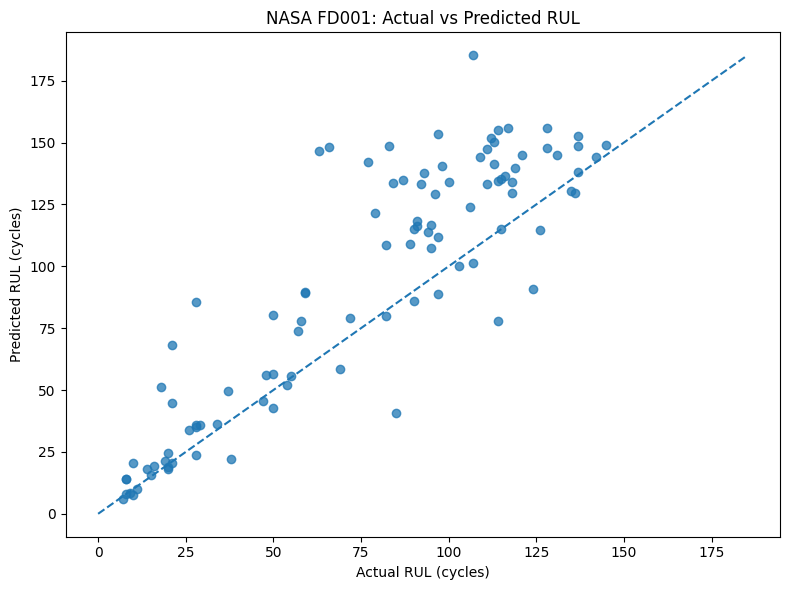

In [0]:
import matplotlib.pyplot as plt

# Convert the 100-row evaluation table to Pandas
plot_df = evaluation.select(
    "unit_number",
    "actual_RUL",
    "predicted_RUL",
    "absolute_error"
).orderBy("unit_number").toPandas()

# Plot actual vs predicted RUL
plt.figure(figsize=(8, 6))
plt.scatter(
    plot_df["actual_RUL"],
    plot_df["predicted_RUL"],
    alpha=0.75
)

# Reference line: perfect predictions
max_value = max(
    plot_df["actual_RUL"].max(),
    plot_df["predicted_RUL"].max()
)
plt.plot([0, max_value], [0, max_value], linestyle="--")

plt.xlabel("Actual RUL (cycles)")
plt.ylabel("Predicted RUL (cycles)")
plt.title("NASA FD001: Actual vs Predicted RUL")
plt.tight_layout()
plt.show()

Top 10 engines with the largest RUL prediction errors:


unit_number,actual_RUL,predicted_RUL,absolute_error
79,63,146.53893760280963,83.53893760280963
27,66,148.19878791956404,82.19878791956404
78,107,185.2743366081911,78.2743366081911
15,83,148.48652261097942,65.48652261097942
67,77,142.3434588296527,65.34345882965269
18,28,85.42930709678134,57.42930709678134
54,97,153.40169340660282,56.40169340660282
16,84,133.63558551885745,49.635585518857454
19,87,135.00094935283565,48.00094935283565
37,21,68.1126213877376,47.112621387737605


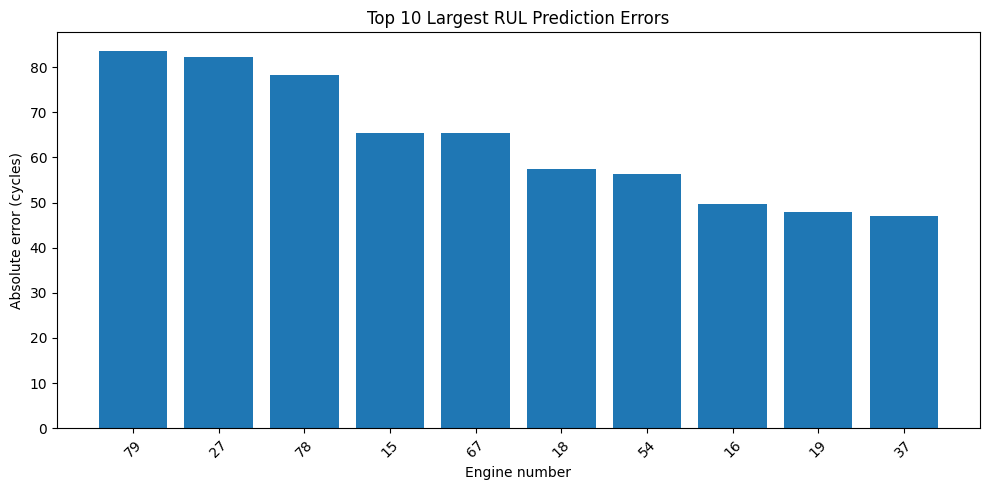

In [0]:
# Find the 10 engines with the largest prediction errors
largest_errors = plot_df.sort_values(
    by="absolute_error",
    ascending=False
).head(10)

print("Top 10 engines with the largest RUL prediction errors:")

display(
    spark.createDataFrame(largest_errors)
    .select(
        "unit_number",
        "actual_RUL",
        "predicted_RUL",
        "absolute_error"
    )
)

# Visualize the errors
plt.figure(figsize=(10, 5))
plt.bar(
    largest_errors["unit_number"].astype(str),
    largest_errors["absolute_error"]
)

plt.xlabel("Engine number")
plt.ylabel("Absolute error (cycles)")
plt.title("Top 10 Largest RUL Prediction Errors")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [0]:
import mlflow
from mlflow.tracking import MlflowClient

run_id = "299f5f156b2a48b6b4d9d90d41b2b943"

client = MlflowClient()

run = client.get_run(run_id)

print("Run ID:", run.info.run_id)
print("Run status:", run.info.status)
print("Logged metrics:", run.data.metrics)

print("\nArtifacts saved in this run:")
for item in client.list_artifacts(run_id):
    print(item.path, "| directory:", item.is_dir)

Run ID: 299f5f156b2a48b6b4d9d90d41b2b943
Run status: FINISHED
Logged metrics: {'validation_MAE': 35.51976673901889, 'validation_R2': 0.5794557544028975, 'validation_RMSE': 50.25359024624587}

Artifacts saved in this run:


Training model for feature-importance analysis...
Top 15 important features:


feature,importance
sensor_4_rolling_avg_3,0.262649760153079
sensor_11_rolling_avg_3,0.16089279849547092
sensor_12_rolling_avg_3,0.08871521172446142
sensor_15_rolling_avg_3,0.08080394775614391
sensor_21_rolling_avg_3,0.07287306055343401
sensor_9_rolling_avg_3,0.07231271948466396
sensor_20_rolling_avg_3,0.0416930404449048
sensor_14_rolling_avg_3,0.028969098927494944
sensor_9,0.02764122070632472
sensor_7_rolling_avg_3,0.025973231551022637


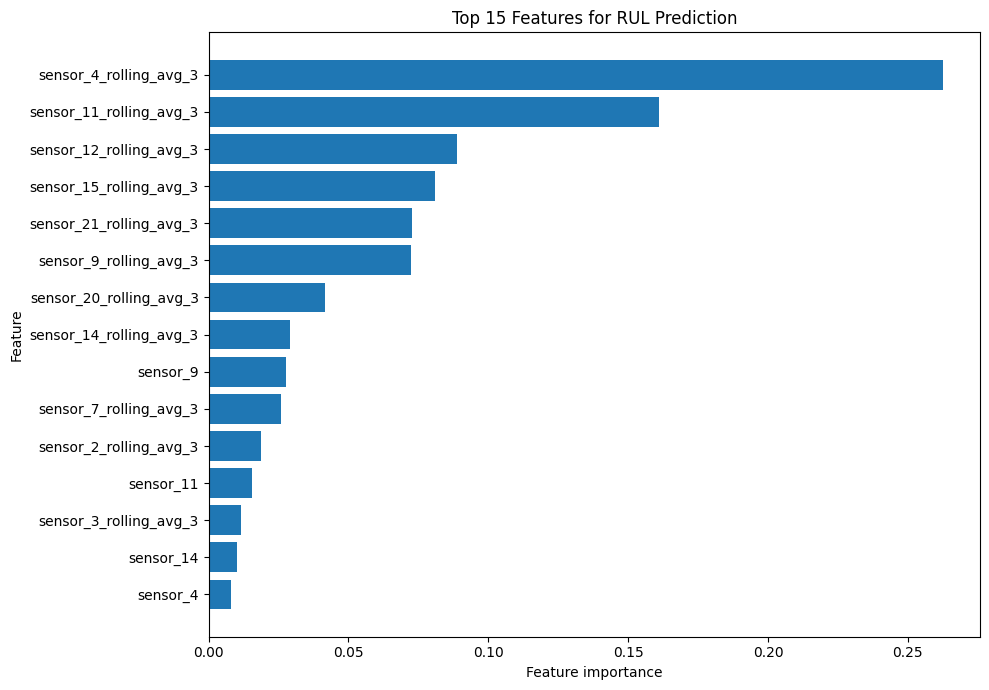

In [0]:

from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, VectorAssembler
from pyspark.ml.regression import RandomForestRegressor
import pandas as pd
import matplotlib.pyplot as plt

schema = "workspace.predictive_maintenance_rul"

# Load the saved Gold training data
gold_train = spark.table(f"{schema}.gold_train_features")

# Define the same 66 input features
feature_cols = (
    [f"op_setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
    + [f"sensor_{i}_rolling_avg_3" for i in range(1, 22)]
    + [f"sensor_{i}_change" for i in range(1, 22)]
)

# Recreate the same split by engine
engine_ids = sorted(
    row["unit_number"]
    for row in gold_train.select("unit_number").distinct().collect()
)

train_engine_ids = engine_ids[:80]

train_df = gold_train.filter(
    F.col("unit_number").isin(train_engine_ids)
)

# Prepare features and target
imputed_features = [f"{c}_imputed" for c in feature_cols]

imputer = Imputer(
    inputCols=feature_cols,
    outputCols=imputed_features,
    strategy="median"
)

assembler = VectorAssembler(
    inputCols=imputed_features,
    outputCol="features",
    handleInvalid="keep"
)

rf = RandomForestRegressor(
    featuresCol="features",
    labelCol="RUL",
    predictionCol="predicted_RUL",
    numTrees=100,
    maxDepth=10,
    seed=42
)

pipeline = Pipeline(stages=[imputer, assembler, rf])

print("Training model for feature-importance analysis...")
analysis_model = pipeline.fit(train_df)

# Extract feature importance
rf_model = analysis_model.stages[-1]

importance_df = pd.DataFrame({
    "feature": feature_cols,
    "importance": rf_model.featureImportances.toArray()
})

top_features = importance_df.sort_values(
    "importance", ascending=False
).head(15)

print("Top 15 important features:")
display(spark.createDataFrame(top_features))

# Plot the results
top_features = top_features.sort_values("importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["feature"], top_features["importance"])
plt.xlabel("Feature importance")
plt.ylabel("Feature")
plt.title("Top 15 Features for RUL Prediction")
plt.tight_layout()
plt.show()


In [0]:
from pyspark.sql import functions as F

# Use the saved official test evaluation
evaluation = spark.table(
    "workspace.predictive_maintenance_rul.gold_test_evaluation"
)

# Assign illustrative priority categories using predicted RUL
maintenance_summary = (
    evaluation
    .withColumn(
        "maintenance_priority",
        F.when(F.col("predicted_RUL") <= 20, "High")
         .when(F.col("predicted_RUL") <= 50, "Medium")
         .otherwise("Low")
    )
)

# Summarize engine counts by priority
priority_counts = (
    maintenance_summary
    .groupBy("maintenance_priority")
    .agg(F.countDistinct("unit_number").alias("engine_count"))
    .orderBy(
        F.when(F.col("maintenance_priority") == "High", 1)
         .when(F.col("maintenance_priority") == "Medium", 2)
         .otherwise(3)
    )
)

display(priority_counts)

# Inspect engines assigned high priority
display(
    maintenance_summary
    .filter(F.col("maintenance_priority") == "High")
    .select(
        "unit_number",
        "predicted_RUL",
        "actual_RUL",
        "absolute_error",
        "maintenance_priority"
    )
    .orderBy("predicted_RUL")
)

maintenance_priority,engine_count
High,12
Medium,16
Low,72


unit_number,predicted_RUL,actual_RUL,absolute_error,maintenance_priority
34,6.171135784911899,7,0.8288642150881014,High
76,7.552273304184764,10,2.447726695815236,High
81,7.802466215912228,8,0.19753378408777156,High
82,8.578202420152174,9,0.4217975798478264,High
35,10.061589122153276,11,0.9384108778467244,High
68,14.087894438934589,8,6.087894438934589,High
31,14.187026053089712,8,6.187026053089712,High
56,15.628225758226643,15,0.6282257582266428,High
100,18.088857174542344,20,1.911142825457656,High
66,18.11849820428368,14,4.118498204283679,High


In [0]:
from pyspark.sql import functions as F

maintenance_summary = (
    spark.table(
        "workspace.predictive_maintenance_rul.gold_test_evaluation"
    )
    .withColumn(
        "maintenance_priority",
        F.when(F.col("predicted_RUL") <= 20, "High")
         .when(F.col("predicted_RUL") <= 50, "Medium")
         .otherwise("Low")
    )
)

(
    maintenance_summary.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable(
        "workspace.predictive_maintenance_rul.gold_maintenance_priority"
    )
)

print("Maintenance-priority table saved successfully.")
print(
    spark.table(
        "workspace.predictive_maintenance_rul.gold_maintenance_priority"
    ).count()
)

Maintenance-priority table saved successfully.
100


In [0]:
from pyspark.sql import functions as F

priority_table = spark.table(
    "workspace.predictive_maintenance_rul.gold_maintenance_priority"
)

print("Total engines:", priority_table.count())

display(
    priority_table.groupBy("maintenance_priority")
    .agg(F.count("*").alias("engine_count"))
    .orderBy("maintenance_priority")
)

display(
    priority_table.select(
        "unit_number",
        "predicted_RUL",
        "actual_RUL",
        "absolute_error",
        "maintenance_priority"
    ).orderBy("unit_number")
)

Total engines: 100


maintenance_priority,engine_count
High,12
Low,72
Medium,16


unit_number,predicted_RUL,actual_RUL,absolute_error,maintenance_priority
1,151.80743830160208,112,39.807438301602076,Low
2,140.7000757291631,98,42.7000757291631,Low
3,58.62785425728279,69,10.372145742717208,Low
4,108.70957947059729,82,26.70957947059729,Low
5,118.32314453217248,91,27.323144532172478,Low
6,137.88848911655674,93,44.88848911655674,Low
7,116.08539250648928,91,25.085392506489285,Low
8,116.68932775511074,95,21.68932775511074,Low
9,133.08384483121054,111,22.08384483121054,Low
10,129.1630912436346,96,33.1630912436346,Low
